In [ ]:
!pip install -q pandas numpy scikit-learn matplotlib seaborn joblib

In [ ]:
import os
import re
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
BASE_PATH = "/content/drive/MyDrive/Smart_Ride_Intelligence"

PROCESSED_PATH = BASE_PATH + "/datasets/processed"
VALIDATED_PATH = PROCESSED_PATH + "/validated"

MODEL_PATH = BASE_PATH + "/models/forum_nlp"
REPORT_PATH = BASE_PATH + "/reports/forum_nlp"

os.makedirs(MODEL_PATH, exist_ok=True)
os.makedirs(REPORT_PATH, exist_ok=True)

print("Paths configured!")

Paths configured!


In [ ]:
posts = pd.read_csv(
    VALIDATED_PATH + "/forum_posts_validated.csv"
)

training_data = pd.read_csv(
    VALIDATED_PATH + "/forum_training_validated.csv"
)

print("Posts shape:", posts.shape)
print("Training data shape:", training_data.shape)

display(training_data.head())

Posts shape: (1000, 22)
Training data shape: (1000, 9)


,post_id,title,text,category,severity,template_id,is_synthetic,combined_text,text_length
0,P00001,Potholes reported near Bhubaneswar road segment,Several potholes are present on the road near ...,Road Hazard,Medium,Road Hazard_01,True,Potholes reported near Bhubaneswar road segmen...,119
1,P00002,Alternative route suggestion,An alternative road near Bhubaneswar road segm...,Route Tip,Low,Route Tip_01,True,Alternative route suggestion An alternative ro...,104
2,P00003,Suggested route for riders,Riders may consider exploring another connecti...,Route Tip,Low,Route Tip_02,True,Suggested route for riders Riders may consider...,111
3,P00004,Unsafe road conditions,The road section near Bhubaneswar road segment...,Safety Concern,Medium,Safety Concern_03,True,Unsafe road conditions The road section near B...,111
4,P00005,Unsafe road conditions,The road section near Bhubaneswar road segment...,Safety Concern,Medium,Safety Concern_03,True,Unsafe road conditions The road section near B...,111


In [ ]:
print("Columns:")
print(training_data.columns.tolist())

Columns:
['post_id', 'title', 'text', 'category', 'severity', 'template_id', 'is_synthetic', 'combined_text', 'text_length']


In [ ]:
def clean_text(text):

    text = str(text).lower()

    # Remove URLs
    text = re.sub(r"http\S+|www\S+", "", text)

    # Remove special characters and numbers
    text = re.sub(r"[^a-z\s]", " ", text)

    # Remove extra spaces
    text = re.sub(r"\s+", " ", text).strip()

    return text

In [ ]:
training_data["combined_text"] = (
    training_data["combined_text"]
    .fillna("")
    .apply(clean_text)
)

training_data["category"] = (
    training_data["category"]
    .fillna("")
    .str.strip()
)

training_data = training_data[
    (training_data["combined_text"] != "") &
    (training_data["category"] != "")
].copy()

print("Prepared dataset shape:", training_data.shape)

display(training_data[["combined_text", "category"]].head())

Prepared dataset shape: (1000, 9)


,combined_text,category
0,potholes reported near bhubaneswar road segmen...,Road Hazard
1,alternative route suggestion an alternative ro...,Route Tip
2,suggested route for riders riders may consider...,Route Tip
3,unsafe road conditions the road section near b...,Safety Concern
4,unsafe road conditions the road section near b...,Safety Concern


,count
category,
Traffic,137
Waterlogging,131
Accident,129
Road Hazard,127
Normal,127
Safety Concern,126
Construction,115
Route Tip,108


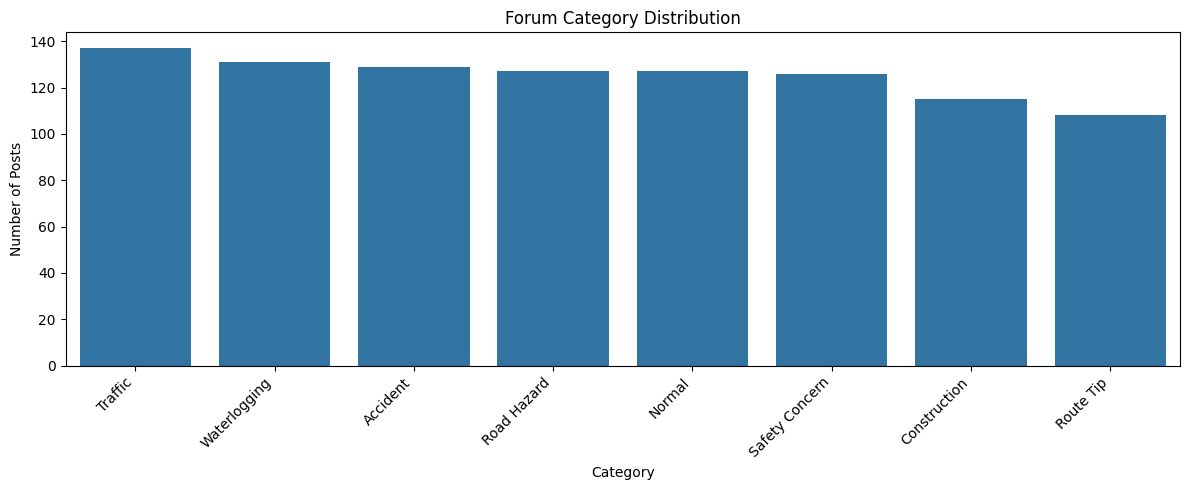

In [ ]:
category_counts = training_data["category"].value_counts()

display(category_counts)

plt.figure(figsize=(12, 5))

sns.barplot(
    x=category_counts.index,
    y=category_counts.values
)

plt.title("Forum Category Distribution")
plt.xlabel("Category")
plt.ylabel("Number of Posts")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.savefig(REPORT_PATH + "/category_distribution.png")
plt.show()

In [ ]:
if "template_id" in training_data.columns:

    template_groups = training_data["template_id"].fillna(
        training_data["post_id"].astype(str)
    )

    unique_templates = template_groups.nunique()

    print("Unique templates:", unique_templates)

    if unique_templates >= 2:

        from sklearn.model_selection import GroupShuffleSplit

        splitter = GroupShuffleSplit(
            n_splits=1,
            test_size=0.20,
            random_state=42
        )

        train_idx, test_idx = next(
            splitter.split(
                training_data,
                training_data["category"],
                groups=template_groups
            )
        )

        train_data = training_data.iloc[train_idx].copy()
        test_data = training_data.iloc[test_idx].copy()

    else:
        raise ValueError(
            "Not enough unique templates for a template-based split."
        )

else:

    raise ValueError(
        "template_id is missing. Use a separate human-written test set "
        "or add template IDs before evaluating the model."
    )

X_train = train_data["combined_text"]
X_test = test_data["combined_text"]

y_train = train_data["category"]
y_test = test_data["category"]

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nTraining categories:")
print(y_train.value_counts())

print("\nTesting categories:")
print(y_test.value_counts())

Unique templates: 34
Training samples: 814
Testing samples: 186

Training categories:
category
Waterlogging      131
Accident          129
Construction      115
Normal            106
Road Hazard        99
Traffic            87
Route Tip          85
Safety Concern     62
Name: count, dtype: int64

Testing categories:
category
Safety Concern    64
Traffic           50
Road Hazard       28
Route Tip         23
Normal            21
Name: count, dtype: int64


In [ ]:
tfidf = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 2),
    stop_words="english",
    min_df=1,
    max_df=0.95,
    sublinear_tf=True
)

X_train_tfidf = tfidf.fit_transform(X_train)

X_test_tfidf = tfidf.transform(X_test)

print("Training matrix shape:", X_train_tfidf.shape)
print("Testing matrix shape:", X_test_tfidf.shape)

Training matrix shape: (814, 265)
Testing matrix shape: (186, 265)


In [ ]:
model = LogisticRegression(
    max_iter=2000,
    class_weight="balanced",
    random_state=42
)

model.fit(X_train_tfidf, y_train)

print("Model training completed!")

Model training completed!


In [ ]:
y_pred = model.predict(X_test_tfidf)

results = pd.DataFrame({
    "Actual_Category": y_test.values,
    "Predicted_Category": y_pred,
    "Post_Text": X_test.values
})

display(results.head(10))

,Actual_Category,Predicted_Category,Post_Text
0,Road Hazard,Normal,uneven road conditions drivers may experience ...
1,Traffic,Traffic,traffic congestion reported a long queue of ve...
2,Route Tip,Route Tip,travel suggestion consider checking alternativ...
3,Safety Concern,Safety Concern,poor street lighting street lighting is descri...
4,Route Tip,Route Tip,travel suggestion consider checking alternativ...
5,Route Tip,Route Tip,travel suggestion consider checking alternativ...
6,Safety Concern,Safety Concern,limited pedestrian visibility pedestrian visib...
7,Normal,Normal,road conditions appear normal the road near bh...
8,Traffic,Normal,slow moving traffic traffic movement is slow n...
9,Normal,Normal,road conditions appear normal the road near bh...


In [ ]:
accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test, y_pred,
    average="weighted",
    zero_division=0
)

recall = recall_score(
    y_test, y_pred,
    average="weighted",
    zero_division=0
)

f1 = f1_score(
    y_test, y_pred,
    average="weighted",
    zero_division=0
)

metrics = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1 Score"],
    "Score": [accuracy, precision, recall, f1]
})

display(metrics)

metrics.to_csv(
    REPORT_PATH + "/forum_model_metrics.csv",
    index=False
)

,Metric,Score
0,Accuracy,0.731183
1,Precision,0.769953
2,Recall,0.731183
3,F1 Score,0.712282


In [ ]:
report = classification_report(
    y_test,
    y_pred,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report).transpose()

display(report_df)

report_df.to_csv(
    REPORT_PATH + "/forum_classification_report.csv"
)

,precision,recall,f1-score,support
Normal,0.295775,1.000000,0.456522,21.000000
Road Hazard,0.000000,0.000000,0.000000,28.000000
Route Tip,1.000000,1.000000,1.000000,23.000000
Safety Concern,1.000000,1.000000,1.000000,64.000000
Traffic,1.000000,0.560000,0.717949,50.000000
accuracy,0.731183,0.731183,0.731183,0.731183
macro avg,0.659155,0.712000,0.634894,186.000000
weighted avg,0.769953,0.731183,0.712282,186.000000


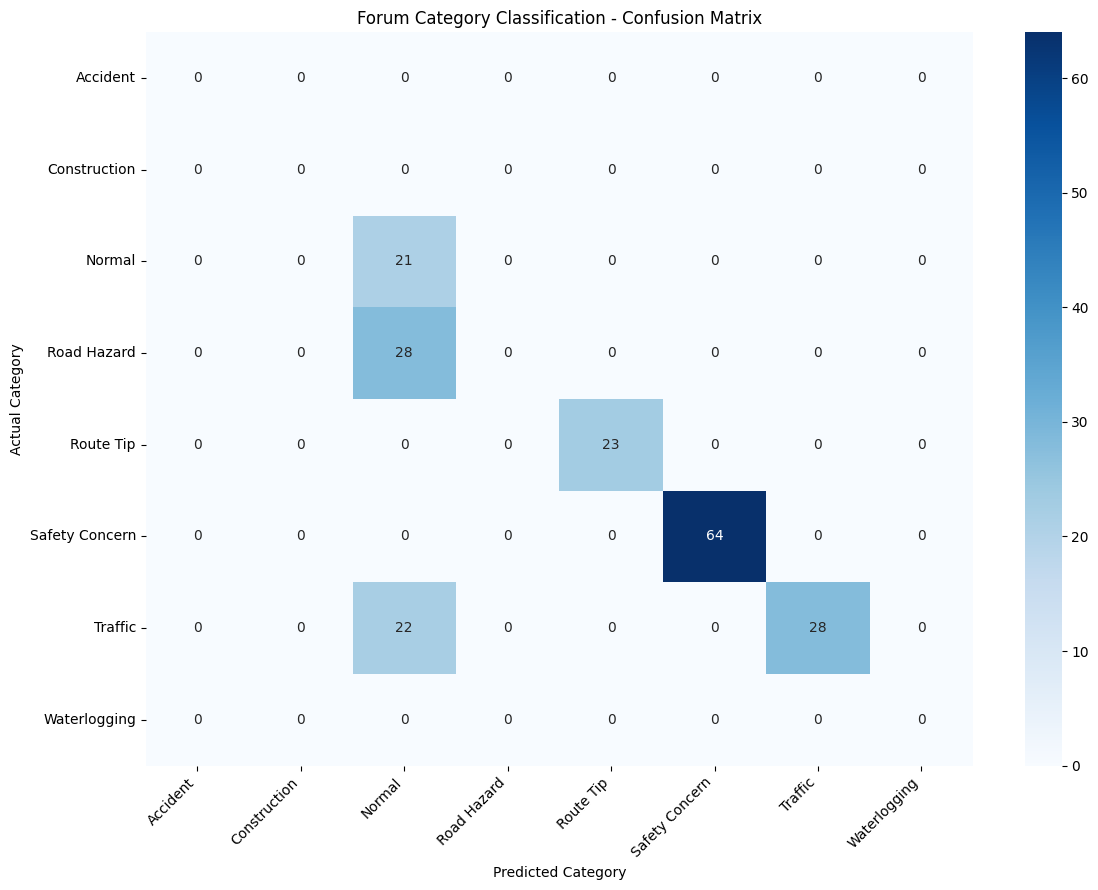

In [ ]:
labels = sorted(training_data["category"].unique())

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=labels
)

plt.figure(figsize=(12, 9))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels
)

plt.title("Forum Category Classification - Confusion Matrix")
plt.xlabel("Predicted Category")
plt.ylabel("Actual Category")

plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()

plt.savefig(
    REPORT_PATH + "/forum_confusion_matrix.png",
    dpi=300
)

plt.show()

In [ ]:
sample_posts = [
    "Heavy traffic near the main road due to a large number of vehicles.",
    "A serious accident has occurred near the flyover.",
    "There is a large pothole on the road. Please drive carefully.",
    "Road construction work is causing delays.",
    "The road is flooded after heavy rainfall.",
    "The route is well lit and feels safe during the evening.",
    "The road surface is damaged and needs repair.",
    "Take the bypass road to avoid the traffic congestion.",
    "Start early in the morning to avoid peak hour traffic.",
    "The journey was smooth and enjoyable.",
    "Normal traffic conditions today."
]

sample_cleaned = [clean_text(text) for text in sample_posts]

sample_vectors = tfidf.transform(sample_cleaned)

sample_predictions = model.predict(sample_vectors)

sample_results = pd.DataFrame({
    "Forum_Post": sample_posts,
    "Predicted_Category": sample_predictions
})

display(sample_results)

,Forum_Post,Predicted_Category
0,Heavy traffic near the main road due to a larg...,Traffic
1,A serious accident has occurred near the flyover.,Accident
2,There is a large pothole on the road. Please d...,Accident
3,Road construction work is causing delays.,Construction
4,The road is flooded after heavy rainfall.,Waterlogging
5,The route is well lit and feels safe during th...,Route Tip
6,The road surface is damaged and needs repair.,Road Hazard
7,Take the bypass road to avoid the traffic cong...,Traffic
8,Start early in the morning to avoid peak hour ...,Traffic
9,The journey was smooth and enjoyable.,Normal


In [ ]:
joblib.dump(
    model,
    MODEL_PATH + "/forum_category_model.pkl"
)

joblib.dump(
    tfidf,
    MODEL_PATH + "/forum_tfidf_vectorizer.pkl"
)

print("Model and vectorizer saved successfully!")

Model and vectorizer saved successfully!


In [ ]:
results.to_csv(
    REPORT_PATH + "/forum_test_predictions.csv",
    index=False
)

In [ ]:
print("Saved model files:")

for file in os.listdir(MODEL_PATH):
    print(file)

print("\nSaved report files:")

for file in os.listdir(REPORT_PATH):
    print(file)

Saved model files:
forum_category_model.pkl
forum_tfidf_vectorizer.pkl

Saved report files:
category_distribution.png
forum_model_metrics.csv
forum_classification_report.csv
forum_confusion_matrix.png
forum_test_predictions.csv


In [ ]:
loaded_model = joblib.load(
    MODEL_PATH + "/forum_category_model.pkl"
)

loaded_tfidf = joblib.load(
    MODEL_PATH + "/forum_tfidf_vectorizer.pkl"
)

test_post = "There is heavy traffic near the main junction."

test_vector = loaded_tfidf.transform([
    clean_text(test_post)
])

prediction = loaded_model.predict(test_vector)

print("Forum Post:", test_post)
print("Predicted Category:", prediction[0])

Forum Post: There is heavy traffic near the main junction.
Predicted Category: Traffic
